# Oklahoma P-Card Exploration — FY2025 (Jul 2024 – Jun 2025)

Source: State of Oklahoma public purchase card data ([data.ok.gov](https://data.ok.gov)), 12 monthly files in `data/raw/fy2025/`.

Note: some filenames don't match their contents (e.g. `pcard_public_202505.csv` holds April 2025 and `pcard_public_20250612180600.csv` holds May 2025), so months are taken from `CALENDAR_YEAR`/`CALENDAR_MONTH`, not the filename.

In [1]:
import glob
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.max_columns', None, 'display.width', 200, 'display.max_colwidth', 60)

FILES = sorted(glob.glob('../data/raw/fy2025/*.csv'))
# utf-8-sig: one file has a BOM; all-strings so nothing is silently coerced
df = pd.concat([pd.read_csv(f, dtype=str, skipinitialspace=True, encoding='utf-8-sig').assign(source_file=f.split('/')[-1]) for f in FILES], ignore_index=True)
df['month'] = df.CALENDAR_YEAR + '-' + df.CALENDAR_MONTH
print(len(FILES), 'files,', df.shape[0], 'rows')
df.groupby('month').size()

12 files, 426637 rows


month
2024-07    34138
2024-08    39103
2024-09    38329
2024-10    40089
2024-11    32347
2024-12    27313
2025-01    33655
2025-02    33083
2025-03    39398
2025-04    39863
2025-05    35264
2025-06    34055
dtype: int64

## 1. Columns & types

In [2]:
df.head()

,CALENDAR_YEAR,CALENDAR_MONTH,AGENCYNBR,AGENCYNAME,LAST_NAME,FIRST_INITIAL,ITEM_DESCR,AMOUNT,MERCHANT,TRANSACTION_DATE,POST_DATE,MCC_DESCRIPTION,ROWID,source_file,month
0,2024,07,01000,OKLAHOMA STATE UNIVERSITY,Tivis,J,Bar Audio Wired In-Ear Hea PCE,24.990000000000000000000000000000000000000000000000000,AMZN Mktp US RC9J295A2,29-Jun-24,01-Jul-24,BOOK STORES,AAAJGhAANAANWuXAAO,pcard_public_202407.csv,2024-07
1,2024,07,01000,OKLAHOMA STATE UNIVERSITY,Tran,M,Holy Stone Mini Drone for PCE|MouseX Wood Traps (P,3943.0600000000000000000000000000000000000000000000000,AMAZON MKTPL RC6DU71U2,28-Jun-24,01-Jul-24,BOOK STORES,AAAJGhAANAANWuXAAP,pcard_public_202407.csv,2024-07
2,2024,07,01000,OKLAHOMA STATE UNIVERSITY,Turner,D,Goniometer Set 3 Pieces 12 PCE,14.980000000000000000000000000000000000000000000000000,AMAZON MKTPL RC9931XA2,28-Jun-24,01-Jul-24,BOOK STORES,AAAJGhAANAANWuXAAQ,pcard_public_202407.csv,2024-07
3,2024,07,01000,OKLAHOMA STATE UNIVERSITY,Ufkes,A,Bronze Monthly item,39.000000000000000000000000000000000000000000000000000,JOTFORM INC,28-Jun-24,01-Jul-24,COMPUTER SOFTWARE STORES,AAAJGhAANAANWuXAAR,pcard_public_202407.csv,2024-07
4,2024,07,01000,OKLAHOMA STATE UNIVERSITY,Vallaster,L,ROOM CHARGES,1211.5500000000000000000000000000000000000000000000000,SHERATON,29-Jun-24,01-Jul-24,SHERATON,AAAJGhAANAANWuXAAS,pcard_public_202407.csv,2024-07


In [3]:
# Clean types (raw load is all strings so nothing is silently coerced)
df['AMOUNT'] = pd.to_numeric(df['AMOUNT'])
df['TRANSACTION_DATE'] = pd.to_datetime(df['TRANSACTION_DATE'], format='%d-%b-%y', errors='coerce')
df['POST_DATE'] = pd.to_datetime(df['POST_DATE'], format='%d-%b-%y', errors='coerce')
df['AGENCYNBR'] = df['AGENCYNBR'].str.strip()
df.dtypes

CALENDAR_YEAR               object
CALENDAR_MONTH              object
AGENCYNBR                   object
AGENCYNAME                  object
LAST_NAME                   object
FIRST_INITIAL               object
ITEM_DESCR                  object
AMOUNT                     float64
MERCHANT                    object
TRANSACTION_DATE    datetime64[ns]
POST_DATE           datetime64[ns]
MCC_DESCRIPTION             object
ROWID                       object
source_file                 object
month                       object
dtype: object

- CALENDAR_YEAR, CALENDAR_MONTH, LAST_NAME, FIRST_INITIAL, TRANSACTION_DATE, POST_DATE
- AGENCYNBR: number identifier for agency name 
- AGENCYNAME: name of the gov agency          
- ITEM_DESCR: what was purchased
- MERCHANT: name of the merchant                    
- MCC_DESCRIPTION: merchant category code (categorization of merchant based on cc company)

In [4]:
summary = pd.DataFrame({
    'non_null': df.notna().sum(),
    'null_pct': (df.isna().mean()*100).round(2),
    'n_unique': df.nunique(),
    'example': df.iloc[0],
})
summary

,non_null,null_pct,n_unique,example
CALENDAR_YEAR,426637,0.00,2,2024
CALENDAR_MONTH,426637,0.00,12,07
AGENCYNBR,426637,0.00,115,01000
AGENCYNAME,426637,0.00,116,OKLAHOMA STATE UNIVERSITY
LAST_NAME,426637,0.00,4419,Tivis
FIRST_INITIAL,426637,0.00,39,J
ITEM_DESCR,426607,0.01,114755,Bar Audio Wired In-Ear Hea PCE
AMOUNT,426637,0.00,93333,24.99
MERCHANT,426637,0.00,145734,AMZN Mktp US RC9J295A2
TRANSACTION_DATE,426637,0.00,400,2024-06-29 00:00:00


**observation**: data is pretty much complete with the except of ITEM_DESCR which is missing 2 values

## 2. Merchant name messiness

Merchant strings look like raw card-processor descriptors (padded, truncated, with trailing reference numbers).

In [5]:
print('Unique MERCHANT strings:', df.MERCHANT.nunique(), 'of', len(df), 'rows')
df.MERCHANT.value_counts().head(25)

Unique MERCHANT strings: 145734 of 426637 rows


MERCHANT
GRAINGER                    9154
WorkQuest-Oklahoma          7387
STAPLES                     5122
NPDB NPDB.HRSA.GOV          4869
LOWES #00241                2726
HOLIDAY INN EXPRESS & SU    2553
HOLIDAY INN EXPRESS         2103
TFS FISHERSCI ECOM HUS      2096
AMAZON MKTPLACE PMTS        1663
WALMART.COM                 1563
MCMASTER-CARR               1460
COX OKLAHOMA COMM SV        1452
ATT BILL PAYMENT            1436
ATT  BILL PAYMENT           1427
SOK RENEWAL DL SERVICES     1313
MMS GOV SOLUTION LLC        1152
HAMPTON INNS                1134
LOWES #00907                1106
WM SUPERCENTER #4241        1104
WAL-MART #4241              1096
HOLIDAY INN EXP & SUITES    1090
AT&T PAYMENT                1088
THE HOME DEPOT #3906        1061
UBER    TRIP                1057
WALMART.COM 8009256278      1022
Name: count, dtype: int64

Light cleanup is not enough: Amazon alone is split across five keys (`AMAZON MKTPL`, `AMZN MKTP US`, `AMAZON.COM`, …). The canonicalizer below does three things:
- strips processor prefixes (`SQ *`, `TST*`, `PAYPAL *`) and tokens containing digits (store numbers, order/ref IDs)
- maps big brands with regex rules
- falls back to the first two words

Truncated names need the MCC to decode (`AMERICAN` is an airline for ~11.5k rows, but a charity/membership org elsewhere), so the airline rules check `MCC_DESCRIPTION`.

**Caveat:** rules are hand-built from the top brands; accuracy has not been measured against a labeled sample.

In [6]:
import re
BRANDS = [(r'^(AMAZON|AMZN)','AMAZON'), (r'^(WAL-?MART|WM SUPERCENTER|WALMART|WM )','WALMART'), (r'^LOWES','LOWES'),
 (r'^(THE )?HOME DEPOT','HOME DEPOT'), (r'^SAMS ?CLUB|^SAMSCLUB','SAMS CLUB'), (r'^(AT&T|ATT )','ATT'), (r'^SOUTHWES','SOUTHWEST AIR'),
 (r'^DELTA AIR','DELTA AIR'), (r'^HOLIDAY INN','HOLIDAY INN'), (r'^HAMPTON','HAMPTON INN'), (r'^HILTON','HILTON'),
 (r'^MARRIOTT|^COURTYARD|^RESIDENCE INN|^FAIRFIELD','MARRIOTT'), (r'^UBER','UBER'), (r'^OFFICE DEPOT','OFFICE DEPOT'),
 (r'^(TFS|FISHER)','FISHER SCI'), (r'^FEDEX|^FED EX','FEDEX')]
AIRLINE_MCC = {'AMERICAN': ('AMERICAN AIRLINES','AMERICAN AIR'), 'UNITED': ('UNITED AIRLINES','UNITED AIR')}

def canon_merchant(raw, mcc):
    u = re.sub(r'^(SQ|TST|PP|PAYPAL|SP|GOOGLE)\s?\*\s?', '', raw.upper())
    for first, (mcc_name, out) in AIRLINE_MCC.items():
        if u.startswith(first) and mcc == mcc_name: return out
    for pat, name in BRANDS:
        if re.match(pat, u): return name
    toks = [t for t in re.sub(r'[^A-Z0-9& ]', ' ', u).split() if not any(c.isdigit() for c in t)]
    return ' '.join(toks[:2]) if toks else u

pairs = df[['MERCHANT','MCC_DESCRIPTION']].drop_duplicates()
pairs['merchant_norm'] = [canon_merchant(m, c) for m, c in zip(pairs.MERCHANT, pairs.MCC_DESCRIPTION)]
df = df.merge(pairs, on=['MERCHANT','MCC_DESCRIPTION'], how='left')

vc = df.merchant_norm.value_counts()
print('unique merchant strings: raw', df.MERCHANT.nunique(), '-> canonical', df.merchant_norm.nunique())
for n in (50, 200, 1000): print(f'top {n} canonical merchants cover {vc.head(n).sum()/len(df):.1%} of rows')
print(f'merchants seen once: {(vc==1).sum()} of {len(vc)} ({(vc==1).sum()/len(df):.1%} of rows)')
vc.head(20)

unique merchant strings: raw 145734 -> canonical 26539
top 50 canonical merchants cover 51.5% of rows
top 200 canonical merchants cover 65.3% of rows
top 1000 canonical merchants cover 79.6% of rows
merchants seen once: 13281 of 26539 (3.1% of rows)


merchant_norm
AMAZON                77776
WALMART               14867
AMERICAN AIR          11602
GRAINGER               9154
LOWES                  8443
HOLIDAY INN            8163
WORKQUEST OKLAHOMA     7387
STAPLES                6227
NPDB NPDB              4869
ATT                    4616
FEDEX                  4170
JOURNYHSE              4086
SOUTHWEST AIR          3984
HAMPTON INN            3607
AGENT FEE              3450
MARRIOTT               2833
FISHER SCI             2692
HILTON                 2394
DELTA AIR              2240
HOME DEPOT             2021
Name: count, dtype: int64

In [7]:
# Sanity checks: Amazon dominance, and canonical keys that may over-merge (many MCCs)
amz = df[df.merchant_norm == 'AMAZON']
print(f'AMAZON: {len(amz)} rows ({len(amz)/len(df):.1%}), ${amz.AMOUNT.sum():,.0f}')
display(amz.MCC_DESCRIPTION.value_counts().head(5))
over = df.groupby('merchant_norm').agg(n=('AMOUNT','size'), n_mcc=('MCC_DESCRIPTION','nunique')).query('n >= 200').sort_values('n_mcc', ascending=False)
over.head(10)  # FRAUD DISPUTE / INC / CITY OF are placeholders or truncation artifacts, not real merchants

AMAZON: 77776 rows (18.2%), $11,116,807


MCC_DESCRIPTION
BOOK STORES                                 63064
VARIETY STORES                               8071
MISCELLANEOUS AND RETAIL STORES              6172
BUSINESS SERVICES NOT ELSEWHERE CLASSIFI      229
LARGE DIGITAL GOODS MERCHANT                  135
Name: count, dtype: int64

,n,n_mcc
merchant_norm,,
FRAUD DISPUTE,380,73
SOUTHWEST AIR,3984,20
HILTON,2394,9
AMAZON,77776,9
CITY OF,848,8
INC,223,8
MARRIOTT,2833,8
HAMPTON INN,3607,7
WALMART,14867,5


## 3. Amounts & categories

In [8]:
df.AMOUNT.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).round(2)

count    426637.00
mean        419.34
std        1961.43
min      -74014.99
1%         -164.51
5%            2.60
25%          35.05
50%         117.98
75%         366.08
95%        1639.81
99%        4535.64
max      470882.00
Name: AMOUNT, dtype: float64

Negative (refunds/credits): 14775 | zero: 0
Total net spend: $178,907,232


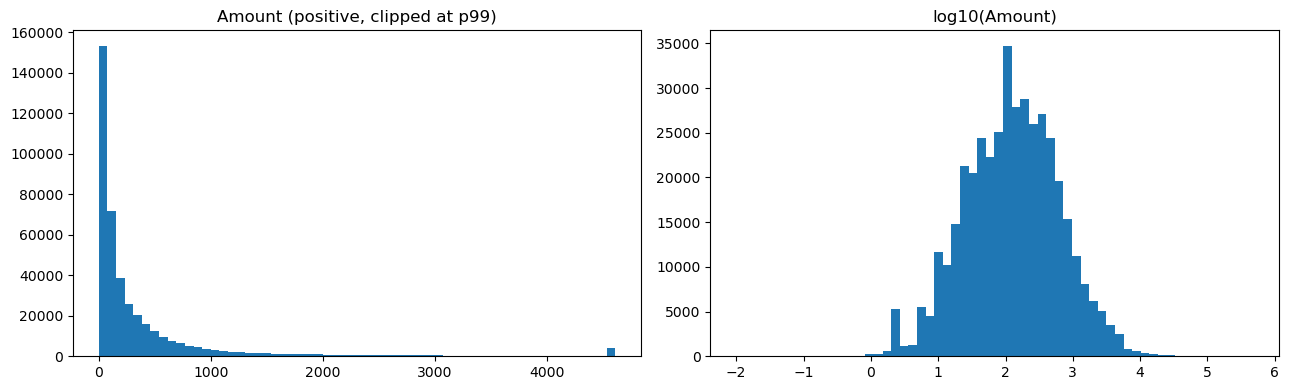

In [9]:
print('Negative (refunds/credits):', (df.AMOUNT<0).sum(), '| zero:', (df.AMOUNT==0).sum())
print('Total net spend: ${:,.0f}'.format(df.AMOUNT.sum()))
fig, ax = plt.subplots(1, 2, figsize=(13,4))
pos = df[df.AMOUNT>0].AMOUNT
ax[0].hist(pos.clip(upper=pos.quantile(.99)), bins=60); ax[0].set_title('Amount (positive, clipped at p99)')
ax[1].hist(np.log10(pos), bins=60); ax[1].set_title('log10(Amount)')
plt.tight_layout()

In [10]:
df.nlargest(15, 'AMOUNT')[['AGENCYNAME','LAST_NAME','MERCHANT','MCC_DESCRIPTION','ITEM_DESCR','AMOUNT','TRANSACTION_DATE']]

,AGENCYNAME,LAST_NAME,MERCHANT,MCC_DESCRIPTION,ITEM_DESCR,AMOUNT,TRANSACTION_DATE
183645,GRAND RIVER DAM AUTH.,Cardholder,BTS GLOBAL RENTAL,CONSTRUCTION MATERIALS,Product EA,470882.00,2024-11-25
19130,OK MEDICAL MARIJUANA AUTHORITY,Hill,TFS FISHERSCI-COG,LAB/MEDICAL/DENTAL/OPHTHALMIC HOSPITAL E,Fisher Scientific Products NMB,327222.56,2024-07-10
425709,GRAND RIVER DAM AUTH.,Cardholder,IN GOLDNER DOCK CONSTRUC,PROFESSIONAL SERVICES NOT ELSEWHERE CLAS,CONSTRUCT AND INSTALL COVE NMB|THE DOCK IS TO BE A,319000.00,2025-05-08
150844,GRAND RIVER DAM AUTH.,Cardholder,ENVIRONMENTAL ACTION INC,SPECIAL TRADE CONTRACTORS,ENVIRONMENTAL ACTION INC EACH,272584.50,2024-10-09
166083,DEPARTMENT OF TRANSPORTATION,Pauley,NUTRIEN AG SOLUTION 1133,AGRICULTURAL COOPERATIVES,GENERAL PURCHASE,176180.40,2024-11-19
425825,GRAND RIVER DAM AUTH.,Cardholder,AMERICAN PUBLIC POWER AS,MEMBERSHIP ORGANIZATIONS NOT ELSEWHERE C,Product EA,171351.63,2025-05-12
239718,UNIV. OF OKLA. HEALTH SCIENCES CENTER,RHONE,PAYMENT ADJUSTMENT,OTHER FEES,GENERAL PURCHASE,164960.94,2024-12-23
90973,DEPARTMENT OF TRANSPORTATION,Welty,FENSCO INC,COMMERCIAL EQUIPMENT NOT ELSEWHERE CLAS,invoice NMB,164608.31,2024-09-06
138621,TULSA COMMUNITY COLLEGE,75000,PAYMENT ADJUSTMENT,OTHER FEES,GENERAL PURCHASE,155934.87,2024-09-16
111282,GRAND RIVER DAM AUTH.,Cardholder,ENVIRONMENTAL ACTION INC,SPECIAL TRADE CONTRACTORS,ENVIRONMENTAL ACTION INC EACH,148747.20,2024-09-27


In [11]:
# AMOUNT is loaded as text; coerce here so this cell works even if the 'Clean types' cell wasn't re-run
amt = pd.to_numeric(df.AMOUNT)
cat = amt.groupby(df.MCC_DESCRIPTION).agg(['count','sum','median','max']).sort_values('count', ascending=False)
print('Distinct MCC descriptions:', len(cat))
cat.round(2).head(20)

Distinct MCC descriptions: 414


,count,sum,median,max
MCC_DESCRIPTION,,,,
BOOK STORES,63580,9324480.36,56.99,19666.48
INDUSTRIAL SUPPLIES NOT ESLEWHERE CLASSI,17140,11008332.22,225.70,112950.00
GROCERY STORES SUPERMARKETS,15080,1381526.13,45.27,4200.00
GOVERNMENT SERVICES NOT ELSEWHERE CLASSI,13713,3413882.98,20.00,33620.00
LAB/MEDICAL/DENTAL/OPHTHALMIC HOSPITAL E,13598,8589843.03,273.30,327222.56
MISCELLANEOUS AND RETAIL STORES,12491,3516546.54,79.96,21534.00
AMERICAN AIRLINES,11547,4607736.89,378.97,15214.71
HOME SUPPLY WAREHOUSE STORES,11053,2727628.28,83.24,74014.99
UTILITIES-ELEC/GAS/HEAT OIL/SANITARY/WTR,10431,4203148.00,151.41,22782.76


In [12]:
print('Distinct ITEM_DESCR:', df.ITEM_DESCR.nunique())
df.ITEM_DESCR.value_counts().head(15)

Distinct ITEM_DESCR: 114755


ITEM_DESCR
GENERAL PURCHASE                 164220
ROOM CHARGES                      33110
AIR TRAVEL                        23733
Order Summary item                13321
Product EA                         2915
PAYMENT ON ACCOUNT EA              1756
Facebook Ads EAC                   1585
ENERGY SERVICES EA                 1542
CAR RENTAL                          988
Eureka Water Company EACH           982
Utility Bill EA                     962
FINANCIAL ACCOUNTING SERVI EA       943
Miscellaneous EA                    933
UBER RIDE EA                        840
Janitorial Supplies CS              748
Name: count, dtype: int64

In [13]:
ag = df.groupby('AGENCYNAME').AMOUNT.agg(['count','sum']).sort_values('sum', ascending=False)
print('Agencies:', len(ag)); ag.head(15).round(0)

Agencies: 116


,count,sum
AGENCYNAME,,
OKLAHOMA STATE UNIVERSITY,111519,33301162.0
DEPARTMENT OF TRANSPORTATION,21715,18506014.0
UNIVERSITY OF OKLAHOMA,57364,15902533.0
DEPARTMENT OF CORRECTIONS,20404,14315496.0
UNIV. OF OKLA. HEALTH SCIENCES CENTER,41104,13594889.0
GRAND RIVER DAM AUTH.,10221,9365614.0
OKLAHOMA MILITARY DEPARTMENT,4935,4101574.0
DEPARTMENT OF REHABILITATION SERVICES,8588,4048017.0
DEPARTMENT OF TOURISM AND RECREATION,9973,3925225.0


count    426637.000000
mean          1.742964
std           2.566895
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         330.000000
Name: post_lag_days, dtype: float64


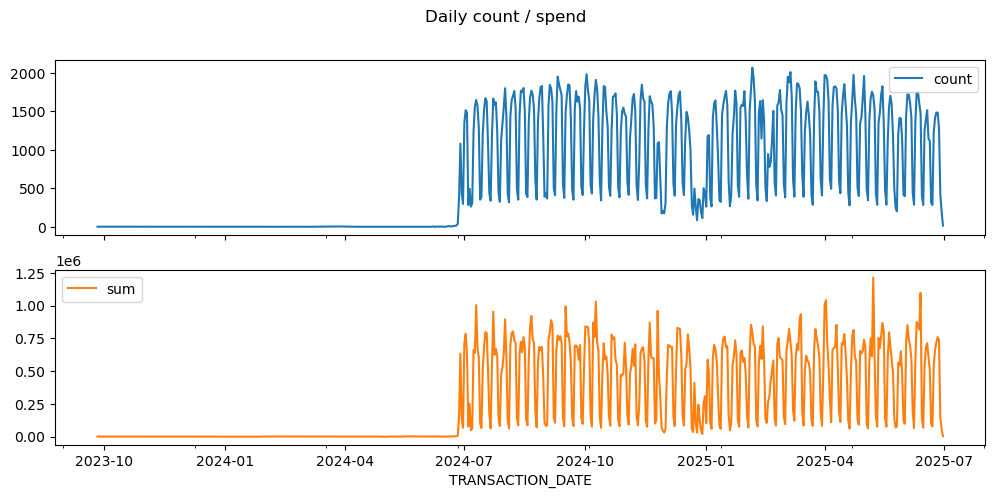

In [14]:
# Posting lag, and weekday/day-of-month patterns
df['post_lag_days'] = (df.POST_DATE - df.TRANSACTION_DATE).dt.days
print(df.post_lag_days.describe())
df.groupby(df.TRANSACTION_DATE.dt.date).AMOUNT.agg(['count','sum']).plot(subplots=True, figsize=(12,5), title='Daily count / spend');

## 4. Can we group by cardholder?

There is **no card number or cardholder ID** — only `AGENCYNBR` + `LAST_NAME` + `FIRST_INITIAL`. Check how well that works as a proxy key, and whether it is ambiguous (two people sharing a last name + initial within an agency).

In [15]:
# Proxy cardholder key: agency NUMBER (agency names have spelling variants) + letters-only upper-cased last name + initial
last = df.LAST_NAME.str.upper().str.replace(r'[^A-Z]', '', regex=True)
init = df.FIRST_INITIAL.fillna('').str.upper()
df['cardholder'] = df.AGENCYNBR + '|' + last + '|' + init
df['bad_initial'] = ~init.str.fullmatch(r'[A-Z]')   # '*', digits, blank -> placeholder / shared card, not a person
# business-name flag must use the ORIGINAL name (stripping punctuation glues words together: 'ANTHONY TRAVEL INC.' -> 'ANTHONYTRAVELINC')
df['biz_name'] = df.LAST_NAME.str.upper().str.contains(r'\b(?:INC|LLC|CORP|TRAVEL|CARDHOLDER|UNIVERSITY|DEPARTMENT)\b', regex=True)
print('Missing last name:', df.LAST_NAME.isna().sum(), '| rows with non-letter initial:', df.bad_initial.sum(), f'({df.bad_initial.mean():.2%})')
print('Distinct proxy cardholders:', df.cardholder.nunique())
per = df.groupby('cardholder').AMOUNT.agg(['count','sum','max'])
print(per['count'].describe().round(1))
per.sort_values('sum', ascending=False).head(15).round(0)

Missing last name: 0 | rows with non-letter initial: 933 (0.22%)
Distinct proxy cardholders: 6318
count    6318.0
mean       67.5
std       185.1
min         1.0
25%         7.0
50%        26.0
75%        73.0
max      7365.0
Name: count, dtype: float64


,count,sum,max
cardholder,,,
98000|CARDHOLDER|E,3545,6790015.0,470882.0
01000|MCCOY|C,6556,2627490.0,15215.0
01000|SCHMITT|A,7365,1828955.0,31553.0
34500|MARTIN|L,94,1713963.0,126748.0
56600|SHAHAN|T,2217,1286303.0,8467.0
04900|PRICE|W,944,1079604.0,45775.0
34500|PAULEY|S,32,1055551.0,176180.0
34500|OSBORNE|H,109,1027160.0,81360.0
01000|CASELMAN|K,2689,996963.0,4995.0


In [16]:
# Cardholder name patterns that signal non-person / shared cards
df.LAST_NAME.str.upper().value_counts().head(15)

LAST_NAME
SCHMITT                7365
MCCOY                  6742
SMITH                  5112
CARDHOLDER             4205
JOHNSON                2758
JONES                  2749
CASELMAN               2726
ANDERSON               2508
HUMBERT                2492
EDWARDS                2380
ANTHONY TRAVEL INC.    2311
SHAHAN                 2279
WINDLE                 2153
DAVIS                  2135
WILLIAMS               2098
Name: count, dtype: int64

### Which proxy keys are not a single person?

Flag keys with a placeholder or business name, extreme volume, or very broad MCC spread. Those are likely shared / department / travel-agency cards, and a per-person baseline over them is meaningless.

In [17]:
g = df.groupby('cardholder').agg(n=('AMOUNT','size'), spend=('AMOUNT','sum'), active_days=('TRANSACTION_DATE','nunique'),
                                n_merchants=('merchant_norm','nunique'), n_mcc=('MCC_DESCRIPTION','nunique'), bad_initial=('bad_initial','any'), biz_name=('biz_name','any'))
g['txns_per_active_day'] = g.n / g.active_days
g['flag_name']    = g.biz_name | g.index.str.contains(r'^\d+\|\d+\|', regex=True)
g['flag_volume']  = (g.n > 2000) | (g.txns_per_active_day > 15)
g['flag_breadth'] = g.n_mcc >= 60
g['non_individual'] = g.flag_name | g.flag_volume | g.flag_breadth | g.bad_initial

fl = g[g.non_individual]
print(f'{len(fl)} of {len(g)} keys ({len(fl)/len(g):.1%}) flagged -> {fl.n.sum()/len(df):.1%} of rows, {fl.spend.sum()/g.spend.sum():.1%} of $')
print(f'keys with <10 txns: {(g.n<10).mean():.0%} of keys but only {g[g.n<10].n.sum()/len(df):.1%} of rows (most volume is baseline-able)')
fl.sort_values('n', ascending=False).head(15).round(1)

54 of 6318 keys (0.9%) flagged -> 10.7% of rows, 13.5% of $
keys with <10 txns: 29% of keys but only 1.8% of rows (most volume is baseline-able)


,n,spend,active_days,n_merchants,n_mcc,bad_initial,biz_name,txns_per_active_day,flag_name,flag_volume,flag_breadth,non_individual
cardholder,,,,,,,,,,,,
01000|SCHMITT|A,7365,1828954.7,348,633,30,False,False,21.2,False,True,False,True
01000|MCCOY|C,6556,2627489.8,299,53,38,False,False,21.9,False,True,False,True
98000|CARDHOLDER|E,3545,6790014.9,259,136,48,False,True,13.7,True,True,False,True
01000|CASELMAN|K,2689,996962.6,253,71,31,False,False,10.6,False,True,False,True
13100|HUMBERT|E,2402,68836.7,206,8,2,False,False,11.7,False,True,False,True
76000|ANTHONYTRAVELINC|G,2311,911249.7,168,8,8,False,True,13.8,True,True,False,True
56600|SHAHAN|T,2217,1286302.7,246,256,70,False,False,9.0,False,True,True,True
76000|WINDLE|C,2153,643992.2,312,440,93,False,False,6.9,False,True,True,True
76000|CHANCE|K,1868,505031.5,306,364,85,False,False,6.1,False,False,True,True


In [18]:
df['non_individual_card'] = df.cardholder.map(g.non_individual)

In [19]:
# Share of all transactions (and $) held by the busiest proxy cardholders
top = g.sort_values('n', ascending=False).head(20)[['n','spend','non_individual']].copy()
top['pct_txns'] = top.n / len(df) * 100
top['cum_pct_txns'] = top.pct_txns.cumsum()
top['pct_spend'] = top.spend / g.spend.sum() * 100
for k in (10, 20):
    print(f'top {k} cardholders: {top.n.head(k).sum()/len(df):.1%} of transactions, {top.spend.head(k).sum()/g.spend.sum():.1%} of $')
top.round(2)

top 10 cardholders: 7.7% of transactions, 9.0% of $
top 20 cardholders: 10.7% of transactions, 11.2% of $


,n,spend,non_individual,pct_txns,cum_pct_txns,pct_spend
cardholder,,,,,,
01000|SCHMITT|A,7365,1828954.67,True,1.73,1.73,1.02
01000|MCCOY|C,6556,2627489.84,True,1.54,3.26,1.47
98000|CARDHOLDER|E,3545,6790014.93,True,0.83,4.09,3.80
01000|CASELMAN|K,2689,996962.60,True,0.63,4.72,0.56
13100|HUMBERT|E,2402,68836.72,True,0.56,5.29,0.04
76000|ANTHONYTRAVELINC|G,2311,911249.66,True,0.54,5.83,0.51
56600|SHAHAN|T,2217,1286302.71,True,0.52,6.35,0.72
76000|WINDLE|C,2153,643992.15,True,0.50,6.85,0.36
76000|CHANCE|K,1868,505031.52,True,0.44,7.29,0.28


In [20]:
# Split-purchase prototype: same cardholder + same merchant + same day, multiple charges
g = (df[df.AMOUNT>0].groupby(['cardholder','merchant_norm','TRANSACTION_DATE'])
       .AMOUNT.agg(n='count', total='sum', max_single='max').reset_index())
split = g[g.n>=2].sort_values('total', ascending=False)
print('Same-day repeat (cardholder, merchant) groups:', len(split))
split.head(15).round(2)

Same-day repeat (cardholder, merchant) groups: 49753


,cardholder,merchant_norm,TRANSACTION_DATE,n,total,max_single
105991,13100|MCKINNIS|R,SOUTH CENTRAL,2024-07-23,55,276099.78,40500.00
211938,75000||7,PAYMENT ADJUSTMENT,2024-09-16,3,190817.47,155934.87
84792,02500|PARRIS|K,LOWES,2025-04-01,3,163556.41,71363.33
151980,34500|WELTY|S,ATT,2024-10-11,4,154407.75,49204.91
84793,02500|PARRIS|K,LOWES,2025-04-02,2,147794.33,74014.99
84794,02500|PARRIS|K,LOWES,2025-04-05,9,145482.93,19840.00
146400,34500|MARTIN|L,ATT,2025-02-04,3,123694.59,49432.11
300362,98000|CARDHOLDER|E,US01MDM,2024-09-03,2,123414.60,98214.60
300120,98000|CARDHOLDER|E,PRYOR STONE,2025-04-14,6,107479.49,106021.60
146403,34500|MARTIN|L,ATT,2025-04-22,2,105257.47,85200.50


,top_mcc,n,top_mcc_share
cardholder,,,
01000|SCHMITT|A,AMERICAN AIRLINES,7365,0.39
01000|MCCOY|C,AMERICAN AIRLINES,6556,0.41
98000|CARDHOLDER|E,INDUSTRIAL SUPPLIES NOT ESLEWHERE CLASSI,3545,0.32
01000|CASELMAN|K,PLUMBING & HEATING EQUIPMENT AND SUPPLIE,2689,0.33
13100|HUMBERT|E,GOVERNMENT SERVICES NOT ELSEWHERE CLASSI,2402,0.61
76000|ANTHONYTRAVELINC|G,AMERICAN AIRLINES,2311,0.44
56600|SHAHAN|T,UTILITIES-ELEC/GAS/HEAT OIL/SANITARY/WTR,2217,0.16
76000|WINDLE|C,BOOK STORES,2153,0.45
76000|CHANCE|K,BOOK STORES,1868,0.51


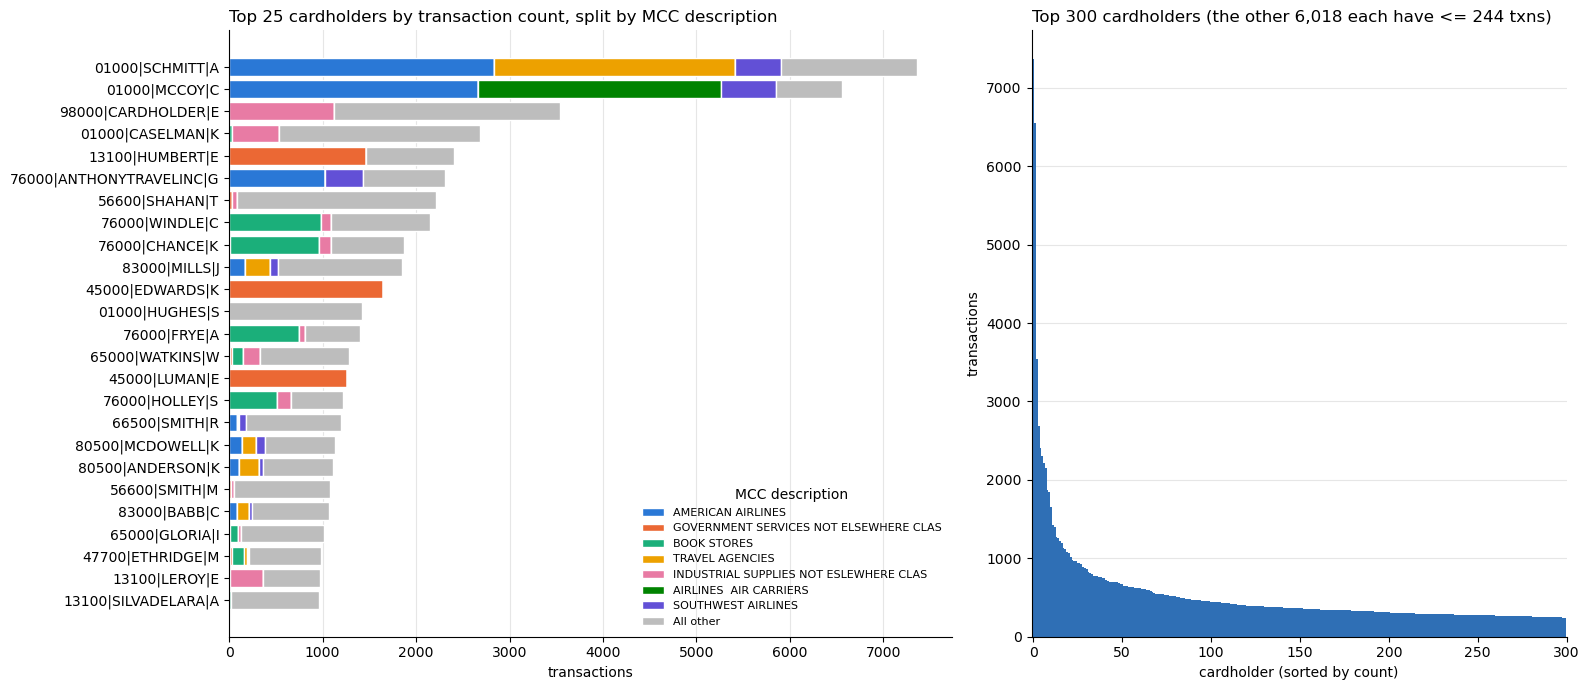

In [21]:
# Transactions per cardholder; top 25 split by MCC description
counts = df.cardholder.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.35, 1]})

# left: top 25 cardholders, each bar split by MCC description
TOP = 25; K = 7                                   # K MCCs get their own color, the rest are grouped as "All other"
top_ids = counts.head(TOP).index
sub = df[df.cardholder.isin(top_ids)]
mix = sub.groupby(['cardholder', 'MCC_DESCRIPTION']).size().unstack(fill_value=0).reindex(top_ids)
keep = mix.sum().sort_values(ascending=False).head(K).index            # most common MCCs across these 25 cardholders
mix = mix[keep].assign(**{'All other': mix.drop(columns=keep).sum(axis=1)})
mix = mix.iloc[::-1]                                                    # busiest on top

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#bdbdbd']   # fixed order; gray = other
left = np.zeros(len(mix))
for col, color in zip(mix.columns, COLORS):
    ax[0].barh(mix.index, mix[col], left=left, color=color, edgecolor='white', linewidth=1, label=col[:38])
    left += mix[col].values
ax[0].set_title(f'Top {TOP} cardholders by transaction count, split by MCC description', loc='left')
ax[0].set_xlabel('transactions')
ax[0].legend(title='MCC description', loc='lower right', fontsize=8, frameon=False)

# right: the 300 busiest cardholders
N = 300
ax[1].bar(range(N), counts.values[:N], width=1.0, color='#2f6fb5')
ax[1].set_title(f'Top {N} cardholders (the other {len(counts)-N:,} each have <= {counts.iloc[N]:,} txns)', loc='left')
ax[1].set_xlabel('cardholder (sorted by count)'); ax[1].set_ylabel('transactions'); ax[1].set_xlim(-1, N)

for a in ax:
    a.grid(True, axis='x' if a is ax[0] else 'y', color='#e6e6e6'); a.set_axisbelow(True)
    for s in ('top', 'right'): a.spines[s].set_visible(False)
plt.tight_layout()

# table: each top cardholder's biggest MCC and its share of their transactions
t = sub.groupby('cardholder').MCC_DESCRIPTION.agg(lambda s: s.value_counts().index[0]).reindex(top_ids).to_frame('top_mcc')
t['n'] = counts.head(TOP)
t['top_mcc_share'] = [sub[(sub.cardholder == c) & (sub.MCC_DESCRIPTION == m)].shape[0] / n for c, m, n in zip(t.index, t.top_mcc, t.n)]
t.round(2)


## 5. Universities only

Same questions as above, restricted to the three large universities: **OSU** (`01000`), **OU** (`76000`) and **OU Health Sciences Center** (`77000`). They are ~50% of all transactions. About ten other universities/colleges are in the data (e.g. `66500` SWOSU, `42000` Langston, `75000` Tulsa CC); add their agency numbers to `UNI` below to widen the scope. Merchant canonicalization and cardholder flags are reused from earlier sections.

In [22]:
UNI = {'01000': 'OSU', '76000': 'OU', '77000': 'OUHSC'}     # add e.g. '66500': 'SWOSU' to widen the scope
df['uni'] = df.AGENCYNBR.map(UNI).fillna('Other agencies')
u = df[df.uni != 'Other agencies']
REPEAT_COLS = ['AGENCYNBR','LAST_NAME','FIRST_INITIAL','ITEM_DESCR','AMOUNT','MERCHANT','TRANSACTION_DATE','POST_DATE','MCC_DESCRIPTION']

def summarize(x):
    pos, ch = x[x.AMOUNT > 0], x.cardholder.value_counts()
    return pd.Series({
        'rows': len(x), 'share of all rows %': len(x)/len(df)*100, 'net $M': x.AMOUNT.sum()/1e6,
        'median charge $': pos.AMOUNT.median(), 'p99 charge $': pos.AMOUNT.quantile(.99), 'credit rows %': (x.AMOUNT < 0).mean()*100,
        'cardholders': len(ch), 'median txns / cardholder': ch.median(), 'top-10 cardholders % of rows': ch.head(10).sum()/len(x)*100,
        'distinct merchants': x.merchant_norm.nunique(), 'Amazon % of rows': (x.merchant_norm == 'AMAZON').mean()*100,
        'GENERAL PURCHASE % of rows': (x.ITEM_DESCR.str.upper() == 'GENERAL PURCHASE').mean()*100,
        'exact-repeat rows %': x.duplicated(REPEAT_COLS).mean()*100})

cols = {**{n: summarize(df[df.uni == n]) for n in UNI.values()}, 'All 3 universities': summarize(u), 'Other agencies': summarize(df[df.uni == 'Other agencies'])}
pd.DataFrame(cols).round(1)

,OSU,OU,OUHSC,All 3 universities,Other agencies
rows,111519.0,57364.0,41104.0,209987.0,216650.0
share of all rows %,26.1,13.4,9.6,49.2,50.8
net $M,33.3,15.9,13.6,62.8,116.1
median charge $,110.0,85.8,104.8,101.4,156.0
p99 charge $,3070.0,3450.0,3686.0,3313.4,5903.0
credit rows %,3.4,3.4,2.7,3.2,3.7
cardholders,2036.0,849.0,512.0,3397.0,2921.0
median txns / cardholder,23.0,26.0,42.0,26.0,26.0
top-10 cardholders % of rows,19.0,21.3,15.5,13.3,8.1
distinct merchants,10616.0,4737.0,2819.0,15653.0,14496.0


uni,OSU,OU,OUHSC
month,,,
2024-07,2.56,1.34,1.21
2024-08,2.96,1.45,1.24
2024-09,2.96,1.34,0.98
2024-10,3.04,1.36,1.15
2024-11,2.36,0.97,1.01
2024-12,1.97,1.18,0.90
2025-01,2.57,1.31,1.14
2025-02,2.72,1.24,0.92
2025-03,3.30,1.46,1.27


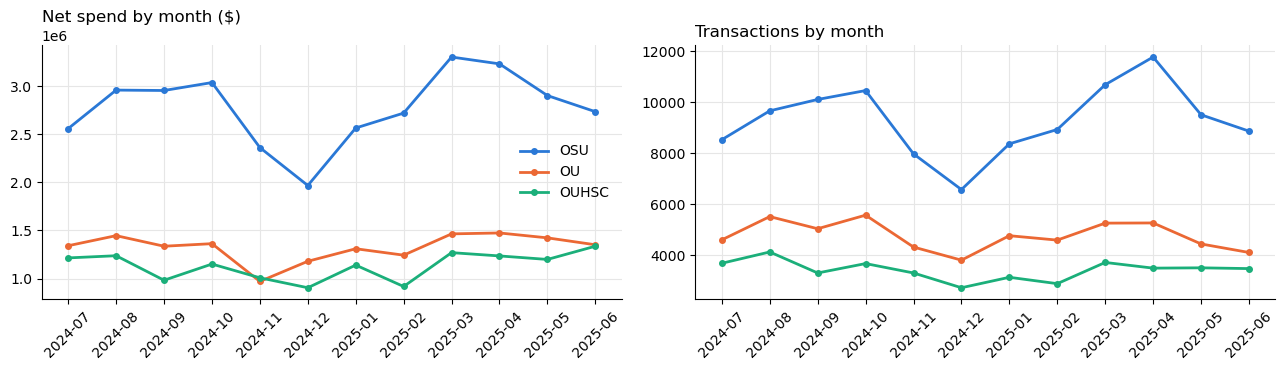

In [23]:
# Monthly pattern per university
UCOL = {'OSU': '#2a78d6', 'OU': '#eb6834', 'OUHSC': '#1baf7a'}
m = df[df.uni.isin(UCOL)].groupby(['month', 'uni']).AMOUNT.agg(rows='size', usd='sum').unstack()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (col, title) in zip(ax, (('usd', 'Net spend by month ($)'), ('rows', 'Transactions by month'))):
    for n, c in UCOL.items(): a.plot(m.index, m[col][n], color=c, lw=2, marker='o', ms=4, label=n)
    a.set_title(title, loc='left'); a.grid(True, color='#e6e6e6'); a.set_axisbelow(True); a.tick_params(axis='x', rotation=45)
    for s in ('top', 'right'): a.spines[s].set_visible(False)
ax[0].legend(frameon=False); plt.tight_layout()
(m.usd / 1e6).round(2)

In [24]:
# Categories & merchants (universities combined), then the top MCCs by $ for each university
def top(x, col, k=10):
    t = x.groupby(col).AMOUNT.agg(rows='size', usd='sum'); t['rows %'] = t.rows / len(x) * 100; t['$ %'] = t.usd / x.AMOUNT.sum() * 100
    return t.sort_values('rows', ascending=False).head(k).round(1)
print('Top MCC descriptions, 3 universities'); display(top(u, 'MCC_DESCRIPTION'))
print('Top canonical merchants, 3 universities'); display(top(u, 'merchant_norm'))
for n in UNI.values(): print(f'\n{n}: top MCCs by $'); display(top(df[df.uni == n], 'MCC_DESCRIPTION', 5).sort_values('usd', ascending=False))

Top MCC descriptions, 3 universities


,rows,usd,rows %,$ %
MCC_DESCRIPTION,,,,
BOOK STORES,47342,6249151.4,22.5,10.0
GROCERY STORES SUPERMARKETS,10791,871681.3,5.1,1.4
LAB/MEDICAL/DENTAL/OPHTHALMIC HOSPITAL E,9909,5179850.8,4.7,8.2
MISCELLANEOUS AND RETAIL STORES,8720,1816888.9,4.2,2.9
AMERICAN AIRLINES,7804,3182967.2,3.7,5.1
VARIETY STORES,6475,892376.2,3.1,1.4
HOME SUPPLY WAREHOUSE STORES,5935,917012.6,2.8,1.5
INDUSTRIAL SUPPLIES NOT ESLEWHERE CLASSI,4928,2063285.7,2.3,3.3
COMPUTER SOFTWARE STORES,3911,1227393.4,1.9,2.0


Top canonical merchants, 3 universities


,rows,usd,rows %,$ %
merchant_norm,,,,
AMAZON,58237,7477884.8,27.7,11.9
WALMART,10786,975272.7,5.1,1.6
AMERICAN AIR,7870,3192500.7,3.7,5.1
LOWES,3676,514489.6,1.8,0.8
FEDEX,3367,396840.8,1.6,0.6
AGENT FEE,2648,17056.4,1.3,0.0
FISHER SCI,2087,804960.7,1.0,1.3
ATT,2048,724847.9,1.0,1.2
HOME DEPOT,1773,249876.3,0.8,0.4



OSU: top MCCs by $


,rows,usd,rows %,$ %
MCC_DESCRIPTION,,,,
AMERICAN AIRLINES,6776,2888331.9,6.1,8.7
BOOK STORES,14232,2045353.4,12.8,6.1
MISCELLANEOUS AND RETAIL STORES,4127,917695.7,3.7,2.8
GROCERY STORES SUPERMARKETS,7664,582873.8,6.9,1.8
HOME SUPPLY WAREHOUSE STORES,3271,456864.3,2.9,1.4



OU: top MCCs by $


,rows,usd,rows %,$ %
MCC_DESCRIPTION,,,,
BOOK STORES,21083,2907458.3,36.8,18.3
INDUSTRIAL SUPPLIES NOT ESLEWHERE CLASSI,1872,779166.1,3.3,4.9
MISCELLANEOUS AND RETAIL STORES,2890,577232.9,5.0,3.6
VARIETY STORES,2393,374338.5,4.2,2.4
HOME SUPPLY WAREHOUSE STORES,2057,334972.3,3.6,2.1



OUHSC: top MCCs by $


,rows,usd,rows %,$ %
MCC_DESCRIPTION,,,,
LAB/MEDICAL/DENTAL/OPHTHALMIC HOSPITAL E,6675,3575416.1,16.2,26.3
BOOK STORES,12027,1296339.7,29.3,9.5
MISCELLANEOUS AND RETAIL STORES,1703,321960.3,4.1,2.4
VARIETY STORES,2165,251765.2,5.3,1.9
GROCERY STORES SUPERMARKETS,1512,187949.3,3.7,1.4


,OSU,OU,OUHSC,Other agencies
cardholders,2036.0,849.0,512.0,2921.0
top-10 % of rows,19.0,21.3,15.5,8.1
top-20 % of rows,22.4,29.1,25.3,12.7
flagged shared/non-person % of rows,14.9,17.7,0.7,8.6
flagged % of $,16.4,21.0,0.6,13.2


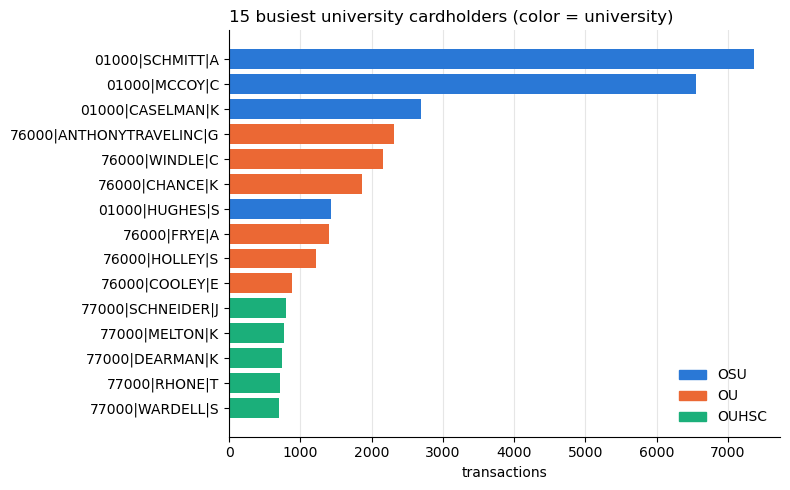

In [25]:
# Cardholders: concentration and shared-card share, per university
rows = {}
for n in list(UNI.values()) + ['Other agencies']:
    x = df[df.uni == n]; c = x.cardholder.value_counts(); f = x[x.non_individual_card.fillna(False)]
    rows[n] = {'cardholders': len(c), 'top-10 % of rows': c.head(10).sum()/len(x)*100, 'top-20 % of rows': c.head(20).sum()/len(x)*100,
               'flagged shared/non-person % of rows': len(f)/len(x)*100, 'flagged % of $': f.AMOUNT.sum()/x.AMOUNT.sum()*100}
display(pd.DataFrame(rows).round(1))

cc = u.cardholder.value_counts().head(15)[::-1]
col = [UCOL[UNI[k.split('|')[0]]] for k in cc.index]
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(cc.index, cc.values, color=col)
ax.set_title('15 busiest university cardholders (color = university)', loc='left'); ax.set_xlabel('transactions')
ax.grid(True, axis='x', color='#e6e6e6'); ax.set_axisbelow(True)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in UCOL.values()], labels=list(UCOL), frameon=False, loc='lower right')
plt.tight_layout()

### Categorization tiers: "Can we tell what this purchase was for?"

Each transaction has three clues: the **merchant name**, the **MCC** (the card network's category label for the merchant), and the **item text** (what the transaction says was bought). Each row gets a tier based on which clues are good enough.

| Tier | In plain English | Example | How we'd categorize it |
|---|---|---|---|
| **A** | The **merchant tells you what it is**. It does one kind of business, and we've seen it plenty of times. | Southwest Airlines, `AIR TRAVEL` → airfare | Simple rule or lookup |
| **A2** | Same as A, but the merchant is **rare** (seen fewer than 5 times), so there's little history. The MCC still tells you the type of business. | A small clothing shop with MCC `CLOTHING STORES` → clothing | Use the MCC |
| **B** | The merchant **sells everything**, so the merchant and MCC don't help. But the **item text says what was bought**. | Amazon, item `Keyboard Wrist Rest PCE` → office supplies | Read the item text |
| **C** | The merchant sells everything **and** the item text is useless. **Nothing in the row says what was bought.** | Walmart, item `GENERAL PURCHASE` | Needs the receipt (or an LLM) |

**How a row gets its tier** (checked in this order):
1. Is the merchant clear and consistent (not Amazon/Walmart-style, not a vague MCC like `MISCELLANEOUS`)? → **A** if we've seen it 5+ times, otherwise **A2**.
2. If not, does the item text actually describe the purchase? → **B**
3. Otherwise → **C**

**Caveats:** this measures how much information a row carries, not how accurate a model would be. The rules are rough guesses, and "item text describes the purchase" only means it isn't filler like `GENERAL PURCHASE`; it's cut off at 50 characters. **Tier C is an upper bound**, because some single-purpose merchants (like `NPDB`) get flagged just for having a vague MCC, and a merchant lookup could handle those once labeled.


In [26]:
# Categorization ambiguity: how much evidence does each row carry? (tiers defined on the whole dataset, compared across groups)
GEN = re.compile(r'^(|GENERAL PURCHASE|ORDER SUMMARY ITEM|PRODUCT( EA[CH]*)?|MISC.*|PAYMENT.*|.*L3 ITEM.*|SERVICES?( EA[CH]*)?|ITEM( EA[CH]*)?|TAX|FEES?)$', re.I)
BIG = {'AMAZON','WALMART','SAMS CLUB','HOME DEPOT','LOWES','TARGET','COSTCO','EBAY','ETSY','PAYPAL','STAPLES','OFFICE DEPOT'}
CATCH = 'NOT ELSEWHERE|ESLEWHERE|MISCELLANEOUS|GENERAL MERCHANDISE|VARIETY|CATALOG|BOOK STORES|WAREHOUSE|DEPARTMENT STORES|DISCOUNT STORES'
generic = df.ITEM_DESCR.fillna('').str.strip().map(lambda s: bool(GEN.match(s)))
top_mcc_share = df.groupby('merchant_norm').MCC_DESCRIPTION.agg(lambda s: s.value_counts(normalize=True).iloc[0])
broad = df.merchant_norm.isin(BIG) | df.MCC_DESCRIPTION.str.contains(CATCH, case=False) | (df.merchant_norm.map(top_mcc_share) < 0.9)
rare = df.merchant_norm.map(df.merchant_norm.value_counts()) < 5
df['tier'] = np.select([~broad & ~rare, ~broad & rare, ~generic], ['A  merchant/MCC decides', 'A2 rare merchant, specific MCC', 'B  broad, item text informative'], 'C  broad + generic item text')
t = pd.crosstab(df.tier, df.uni, normalize='columns') * 100
t['All 3 universities'] = df[df.uni != 'Other agencies'].tier.value_counts(normalize=True) * 100
t.round(1)  # % of rows. Tier C is an upper bound (catch-all MCCs also pull in single-purpose merchants)

uni,OSU,OU,OUHSC,Other agencies,All 3 universities
tier,,,,,
A merchant/MCC decides,46.4,25.5,38.4,46.5,39.1
"A2 rare merchant, specific MCC",7.1,4.6,4.4,5.2,5.9
"B broad, item text informative",24.7,49.3,39.3,25.3,34.3
C broad + generic item text,21.8,20.6,17.9,23.1,20.7


### Takeaways: universities

- **Size:** the three universities are 49% of rows but 35% of dollars ($62.8M of $178.9M). Tickets are smaller: median charge $101 vs $156 elsewhere, p99 $3.3k vs $5.9k.
- **Amazon-heavy:** Amazon is 28% of university rows (OU 44%, OUHSC 37%, OSU 16%) vs 9% elsewhere. The top MCC, `BOOK STORES` (22.5% of rows), is mostly Amazon.
- **Each looks different:** OSU is travel-heavy (American Airlines is its top MCC by $, 8.7%); OU is Amazon/marketplace (37% of rows under `BOOK STORES`); OUHSC is lab/medical equipment (26% of its $).
- **Cardholders:** 3,397 keys. The top 10 hold 15–21% of each university's rows. Shared/non-person flags cover 15% (OSU) and 18% (OU) of rows but only 0.7% at OUHSC, so per-person baselines are most viable there.
- **Repeats:** exact-repeat rows are 2.5% at universities vs 9.6% elsewhere (the per-lookup fee merchants like NPDB are mostly outside universities).
- **Categorization:** the share needing a receipt/LLM (tier C) is similar (20.7% vs 23.1%), but the mix differs. OU is 49% tier B (Amazon rows whose item text names the product) and only 26% tier A, so item-text classification matters most there. OSU looks like the non-university average.
- **Seasonality:** same shape as the whole dataset: December low, peaks in Mar-Apr and Aug-Oct.

## 6. OSU only

Oklahoma State University (agency `01000`) is the largest single agency: about a quarter of all transactions. Same questions as above, compared against OU + OUHSC and the non-university agencies. Relies on `df`, `uni`, `tier`, `cardholder` and `non_individual_card` from the earlier sections, so run those first (or Restart & Run All).

1. Headline


,OSU,OU + OUHSC,Other agencies
rows,111519.0,98468.0,216650.0
net $M,33.3,29.5,116.1
median charge $,110.0,93.6,156.0
p99 charge $,3070.0,3574.5,5903.0
credit rows %,3.4,3.1,3.7
cardholders,2036.0,1361.0,2921.0
median txns / cardholder,23.0,31.0,26.0
Amazon % of rows,16.0,41.1,9.0
exact-repeat rows %,3.8,1.1,9.6


2. Monthly pattern


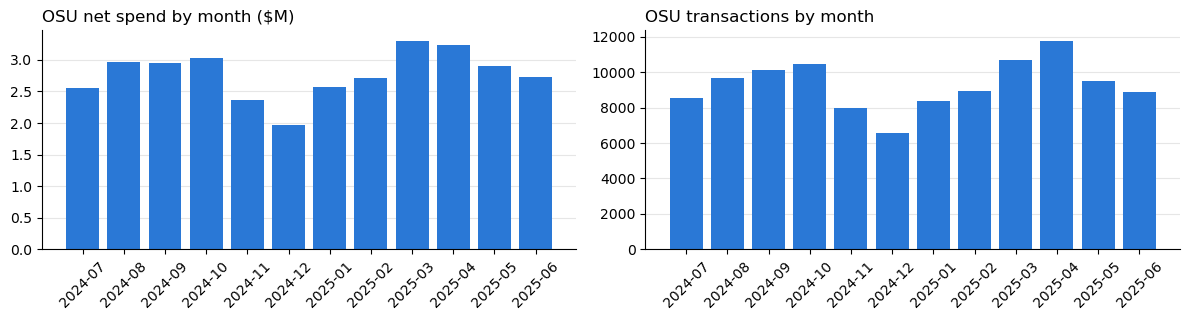

3. Top MCCs by $


,rows,usd,rows %,$ %
MCC_DESCRIPTION,,,,
AMERICAN AIRLINES,6776,2888331.9,6.1,8.7
BOOK STORES,14232,2045353.4,12.8,6.1
LAB/MEDICAL/DENTAL/OPHTHALMIC HOSPITAL E,2267,1166267.9,2.0,3.5
INDUSTRIAL SUPPLIES NOT ESLEWHERE CLASSI,2320,918095.0,2.1,2.8
MISCELLANEOUS AND RETAIL STORES,4127,917695.7,3.7,2.8
EATING PLACES RESTAURANTS,2860,891210.1,2.6,2.7
BUSINESS SERVICES NOT ELSEWHERE CLASSIFI,1838,858593.3,1.6,2.6
CHARITABLE AND SOCIAL SERVICE ORGANIZATI,1476,783042.3,1.3,2.4
MEMBERSHIP ORGANIZATIONS NOT ELSEWHERE C,1531,750833.4,1.4,2.3


   Top merchants by $


,rows,usd,rows %,$ %
merchant_norm,,,,
AMERICAN AIR,6842,2897865.4,6.1,8.7
AMAZON,17792,2470250.8,16.0,7.4
WALMART,8222,696965.2,7.4,2.1
SOUTHWEST AIR,1144,621398.2,1.0,1.9
DELTA AIR,897,439855.2,0.8,1.3
MARRIOTT,739,427084.6,0.7,1.3
UNITED AIR,894,397728.8,0.8,1.2
LOWES,2964,396569.2,2.7,1.2
HILTON,641,359329.4,0.6,1.1


4. Cardholders
2036 cardholders | top-10 hold 19.0% of rows, top-20 22.4% | flagged shared/non-person: 3 keys = 14.9% of rows, 16.4% of $


,txns,usd,n_mcc,top_mcc,flagged
cardholder,,,,,
01000|SCHMITT|A,7365,1828955.0,30,AMERICAN AIRLINES,True
01000|MCCOY|C,6556,2627490.0,38,AMERICAN AIRLINES,True
01000|CASELMAN|K,2689,996963.0,31,PLUMBING & HEATING EQUIPMENT AND,True
01000|HUGHES|S,1424,144176.0,14,GROCERY STORES SUPERMARKETS,False
01000|HIGDON|C,625,249916.0,57,BOOK STORES,False
01000|TURNER|D,578,141530.0,45,BOOK STORES,False
01000|BLAKLEY|T,571,208736.0,53,BOOK STORES,False
01000|STANUSHCH|S,497,112467.0,26,AMERICAN AIRLINES,False
01000|BULLARD|T,467,145105.0,45,TRANSPORTATION SERVICES NOT ELSE,False


... (4 outputs left out)

6. Large charges and the $5,000 line


,LAST_NAME,MERCHANT,MCC_DESCRIPTION,ITEM_DESCR,AMOUNT,TRANSACTION_DATE
159443,Yeats CH,MARRIOTT NORTH CHARLES,MARRIOTT,ROOM CHARGES,63111.15,2024-11-24
155143,Smith,PRIME TIME TRAVEL,TRAVEL AGENCIES,GENERAL PURCHASE,34226.40,2024-11-12
397985,Norris CH,HILTON GARDEN INN,HILTON GARDEN INN,ROOM CHARGES,33972.57,2025-05-19
186990,Andersson,Vista Outdoors,SPORTING GOODS STORES,GENERAL PURCHASE,33500.00,2024-12-11
246251,Schmitt,SOUTHWES 5262306655160,SOUTHWEST AIRLINES,AIR TRAVEL,31553.45,2025-02-03
153484,Hoyt CH,HILTON HOTELS,HILTON,ROOM CHARGES,26325.86,2024-11-06
252558,Schmitt,SOUTHWES 5262314485631,SOUTHWEST AIRLINES,AIR TRAVEL,21044.25,2025-02-24
152132,Yeats CH,MARRIOTT NORTH CHARLES,MARRIOTT,ROOM CHARGES,18070.42,2024-11-01
36015,McGuire,THE NEW YORKER HOTEL,LODGING HOTELS MOTELS RESORTS,ROOM CHARGES,18053.96,2024-08-05
279274,Schmitt,SOUTHWES 5262317705967,SOUTHWEST AIRLINES,AIR TRAVEL,17242.00,2025-03-03


charges $4,500-4,999: 177 | $5,000-5,499: 50 | exactly $5,000: 25
   Most repeated identical charges (merchants):


merchant_norm
HOLIDAY INN        313
HTTPS ECOMMERCE    229
MARRIOTT           175
HILTON             157
HAMPTON INN        152
Name: count, dtype: int64

In [27]:
# ---- OSU deep dive (agency 01000) ----
osu = df[df.AGENCYNBR == '01000']
groups = {'OSU': osu, 'OU + OUHSC': df[df.uni.isin(['OU', 'OUHSC'])], 'Other agencies': df[df.uni == 'Other agencies']}

def head(x):
    pos, ch = x[x.AMOUNT > 0], x.cardholder.value_counts()
    return pd.Series({'rows': len(x), 'net $M': x.AMOUNT.sum()/1e6, 'median charge $': pos.AMOUNT.median(), 'p99 charge $': pos.AMOUNT.quantile(.99),
                      'credit rows %': (x.AMOUNT < 0).mean()*100, 'cardholders': len(ch), 'median txns / cardholder': ch.median(),
                      'Amazon % of rows': (x.merchant_norm == 'AMAZON').mean()*100, 'exact-repeat rows %': x.duplicated(REPEAT_COLS).mean()*100})
print('1. Headline'); display(pd.DataFrame({k: head(v) for k, v in groups.items()}).round(1))

print('2. Monthly pattern')
mo = osu.groupby('month').AMOUNT.agg(rows='size', usd='sum')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].bar(mo.index, mo.usd/1e6, color='#2a78d6'); ax[0].set_title('OSU net spend by month ($M)', loc='left')
ax[1].bar(mo.index, mo.rows, color='#2a78d6'); ax[1].set_title('OSU transactions by month', loc='left')
for a in ax:
    a.tick_params(axis='x', rotation=45); a.grid(True, axis='y', color='#e6e6e6'); a.set_axisbelow(True)
    for s in ('top', 'right'): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

def top(x, col, k=10, by='usd'):
    t = x.groupby(col).AMOUNT.agg(rows='size', usd='sum'); t['rows %'] = t.rows/len(x)*100; t['$ %'] = t.usd/x.AMOUNT.sum()*100
    return t.sort_values(by, ascending=False).head(k).round(1)
print('3. Top MCCs by $'); display(top(osu, 'MCC_DESCRIPTION'))
print('   Top merchants by $'); display(top(osu, 'merchant_norm'))

print('4. Cardholders')
c = osu.cardholder.value_counts(); fl = osu[osu.non_individual_card.fillna(False)]
print(f'{len(c)} cardholders | top-10 hold {c.head(10).sum()/len(osu):.1%} of rows, top-20 {c.head(20).sum()/len(osu):.1%} | flagged shared/non-person: {fl.cardholder.nunique()} keys = {len(fl)/len(osu):.1%} of rows, {fl.AMOUNT.sum()/osu.AMOUNT.sum():.1%} of $')
ch = osu.groupby('cardholder').agg(txns=('AMOUNT', 'size'), usd=('AMOUNT', 'sum'), n_mcc=('MCC_DESCRIPTION', 'nunique'),
                                   top_mcc=('MCC_DESCRIPTION', lambda s: s.value_counts().index[0][:32]), flagged=('non_individual_card', 'first'))
display(ch.sort_values('txns', ascending=False).head(12).round(0))

print('5. Categorization tiers (OSU)')
t = osu.groupby('tier').AMOUNT.agg(rows='size', usd='sum'); t['rows %'] = t.rows/len(osu)*100; t['$ %'] = t.usd/osu.AMOUNT.sum()*100; display(t.round(1))
print('   Biggest tier-C merchants'); display(top(osu[osu.tier.str.startswith('C')], 'merchant_norm', 8, by='rows'))

print('6. Large charges and the $5,000 line')
display(osu.nlargest(10, 'AMOUNT')[['LAST_NAME', 'MERCHANT', 'MCC_DESCRIPTION', 'ITEM_DESCR', 'AMOUNT', 'TRANSACTION_DATE']])
print(f"charges $4,500-4,999: {osu.AMOUNT.between(4500, 4999.99).sum()} | $5,000-5,499: {osu.AMOUNT.between(5000, 5499.99).sum()} | exactly $5,000: {(osu.AMOUNT == 5000).sum()}")
print('   Most repeated identical charges (merchants):'); display(osu[osu.duplicated(REPEAT_COLS)].merchant_norm.value_counts().head(5))


### Takeaways: OSU

- **Size:** 111,519 rows (26% of all) and $33.3M (19% of dollars). Typical charges are small (median $110) and the 99th percentile is $3,070 vs $5,903 at non-university agencies.
- **Travel is its signature:** American Airlines is both the top merchant and top MCC by dollars (8.7%), followed by Southwest, Delta, United and the hotel chains. Amazon is #1 by row count (16%) but second by dollars (7.4%), and it is far less Amazon-heavy than OU/OUHSC (16% vs 41% of rows).
- **Cardholders:** 2,036 keys; the top 10 hold 19% of rows. Three flagged keys (`SCHMITT` 7,365 rows, `MCCOY` 6,556, `CASELMAN` 2,689) account for 14.9% of rows and 16.4% of dollars. SCHMITT and MCCOY are mostly American Airlines, which fits shared travel-booking cards.
- **Categorization:** 46% of rows are tier A and 7% A2. Tier C is 22% of rows, and Walmart (34% of tier C) and Amazon (17%) are the two largest sources. Walmart rows have no item text at all.
- **Large charges:** the ten biggest are mostly lodging and airfare (e.g. a $63,111 Marriott North Charles room charge and $33,973 at Hilton Garden Inn), with one non-travel exception ($33,500 at Vista Outdoors).
- **The $5,000 line:** 177 charges fall in $4,500-4,999 vs 50 in $5,000-5,499 (25 exactly $5,000), the same pile-up just under $5,000 seen in the whole dataset.
- **Repeats:** 3.8% of rows are exact repeats, mostly multi-night hotel stays (Holiday Inn, Marriott, Hilton, Hampton Inn).